# ACP Airbnb Paris - Etape 1 : comprehension du dataset

Ce notebook se concentre uniquement sur une **premiere lecture du dataset**.

Objectifs de cette etape :
- charger le fichier CSV ;
- observer la dimension du jeu de donnees ;
- afficher un apercu des lignes ;
- examiner les types de variables ;
- compter les valeurs manquantes ;
- resumer les variables numeriques ;
- reperer les colonnes qui semblent numeriques mais sont encore stockees en texte ;
- separer, dans une premiere lecture, les variables numeriques et categorielles.

Important :
- on **ne nettoie pas** encore les donnees ;
- on ne lance **pas** l'ACP a cette etape ;
- on ne fait ni standardisation ni apprentissage supervise.

In [26]:
# Import des bibliotheques utiles pour cette premiere exploration.
from pathlib import Path

import pandas as pd

# Options d'affichage pour rendre les tableaux plus lisibles dans le notebook.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)


In [27]:
# On definit un chemin robuste vers le fichier CSV.
# Le notebook est place dans le dossier `notebooks/`, mais on garde une solution souple
# au cas ou l'execution se ferait depuis un autre repertoire.
csv_path = Path("../paris_airbnb.csv")
if not csv_path.exists():
    csv_path = Path("paris_airbnb.csv")

# Chargement du dataset sans transformation ni nettoyage.
df = pd.read_csv(csv_path)

print(f"Fichier charge : {csv_path.resolve()}")


Fichier charge : C:\Users\user\Desktop\Edam\ids3\S2\stat multivariee\projet\paris_airbnb.csv


In [28]:
# 1. Dimension du dataset
print("Dimension du dataset (lignes, colonnes) :", df.shape)

# 2. Apercu des 5 premieres lignes
display(df.head())


Dimension du dataset (lignes, colonnes) : (8000, 19)


,host_response_rate,host_acceptance_rate,host_listings_count,latitude,longitude,city,zipcode,state,accommodates,room_type,bedrooms,bathrooms,beds,price,cleaning_fee,security_deposit,minimum_nights,maximum_nights,number_of_reviews
0,100%,NaN,1.0,48.83349,2.31852,Paris,75014,Île-de-France,2,Entire home/apt,0.0,1.0,0.0,$75.00,$50.00,$0.00,3,15,8
1,100%,NaN,1.0,48.85100,2.35869,Paris,75004,Ile-de-France,2,Entire home/apt,0.0,1.0,1.0,$115.00,$36.00,$0.00,1,90,173
2,100%,NaN,2.0,48.85758,2.35275,Paris,75004,Île-de-France,4,Entire home/apt,2.0,1.0,2.0,$115.00,$50.00,$200.00,10,23,243
3,100%,NaN,1.0,48.86528,2.39326,Paris,75020,Ile-de-France,3,Entire home/apt,1.0,1.0,1.0,$90.00,NaN,NaN,3,365,1
4,67%,NaN,3.0,48.85899,2.34735,Paris,75001,Île-de-France,2,Entire home/apt,1.0,1.0,1.0,$75.00,$200.00,"$1,500.00",180,365,0


In [29]:
# 3. Types de variables
# `info()` donne une vue d'ensemble du dataset : nombre de valeurs non nulles et types.
df.info()

# `dtypes` donne ensuite une vue concise colonne par colonne.
display(df.dtypes.rename("type"))

# 4. Nombre de valeurs manquantes par colonne
missing_values = df.isna().sum().sort_values(ascending=False)
display(missing_values.rename("missing_values"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   host_response_rate    5000 non-null   object 
 1   host_acceptance_rate  0 non-null      float64
 2   host_listings_count   7999 non-null   float64
 3   latitude              8000 non-null   float64
 4   longitude             8000 non-null   float64
 5   city                  7997 non-null   object 
 6   zipcode               7930 non-null   object 
 7   state                 7977 non-null   object 
 8   accommodates          8000 non-null   int64  
 9   room_type             8000 non-null   object 
 10  bedrooms              7976 non-null   float64
 11  bathrooms             7942 non-null   float64
 12  beds                  7986 non-null   float64
 13  price                 8000 non-null   object 
 14  cleaning_fee          6250 non-null   object 
 15  security_deposit     

host_response_rate       object
host_acceptance_rate    float64
host_listings_count     float64
latitude                float64
longitude               float64
city                     object
zipcode                  object
state                    object
accommodates              int64
room_type                object
bedrooms                float64
bathrooms               float64
beds                    float64
price                    object
cleaning_fee             object
security_deposit         object
minimum_nights            int64
maximum_nights            int64
number_of_reviews         int64
Name: type, dtype: object

host_acceptance_rate    8000
host_response_rate      3000
cleaning_fee            1750
security_deposit        1680
zipcode                   70
bathrooms                 58
bedrooms                  24
state                     23
beds                      14
city                       3
host_listings_count        1
room_type                  0
accommodates               0
longitude                  0
latitude                   0
price                      0
minimum_nights             0
maximum_nights             0
number_of_reviews          0
Name: missing_values, dtype: int64

In [30]:
# 5. Resume statistique des variables numeriques deja reconnues comme telles.
# Cette etape permet d'identifier rapidement les ordres de grandeur,
# les valeurs minimales / maximales et les ecarts possibles entre variables.
numeric_summary = df.describe()
display(numeric_summary)


,host_acceptance_rate,host_listings_count,latitude,longitude,accommodates,bedrooms,bathrooms,beds,minimum_nights,maximum_nights,number_of_reviews
count,0.0,7999.000000,8000.000000,8000.000000,8000.000000,7976.000000,7942.000000,7986.000000,8000.000000,8000.000000,8000.000000
mean,NaN,7.025878,48.864560,2.348739,3.198750,1.248370,1.128494,1.753068,8.759375,546.876000,44.874875
std,NaN,51.031588,0.017641,0.031611,1.569811,0.838492,0.439104,1.172800,36.234546,542.848736,69.075322
min,NaN,0.000000,48.816560,2.230810,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,NaN,1.000000,48.852230,2.331645,2.000000,1.000000,1.000000,1.000000,2.000000,30.000000,4.000000
50%,NaN,1.000000,48.865400,2.351130,3.000000,1.000000,1.000000,1.000000,3.000000,365.000000,19.000000
75%,NaN,2.000000,48.878740,2.372158,4.000000,2.000000,1.000000,2.000000,5.000000,1125.000000,54.000000
max,NaN,836.000000,48.901010,2.439460,16.000000,7.000000,7.000000,11.000000,1124.000000,10000.000000,783.000000


In [31]:
# 6. Reperage des colonnes qui semblent numeriques mais sont stockees en texte.
# Exemple typique : prix avec symbole monetaire, pourcentages, codes postaux en texte.

def normalize_numeric_text(series: pd.Series) -> pd.Series:
    """Nettoie legerement une serie texte pour tester si elle ressemble a du numerique.
    Cette fonction sert uniquement au diagnostic et ne modifie pas le dataset d'origine.
    """
    cleaned = (
        series.astype("string")
        .str.strip()
        .str.replace("\u00A0", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(",", ".", regex=False)
        .str.replace("%", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace(r"[^0-9.\-]", "", regex=True)
    )
    return cleaned


text_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()
suspected_numeric_text = []

for column in text_columns:
    non_null_values = df[column].dropna()

    # Si la colonne est vide une fois les NA retires, on ne peut pas conclure.
    if non_null_values.empty:
        continue

    normalized_values = normalize_numeric_text(non_null_values)
    converted_values = pd.to_numeric(normalized_values, errors="coerce")
    parseable_ratio = converted_values.notna().mean()

    # Seuil simple : si la grande majorite des valeurs texte peut etre lue comme numerique,
    # on considere que la colonne merite une verification a l'etape suivante.
    if parseable_ratio >= 0.80:
        suspected_numeric_text.append(
            {
                "column": column,
                "parseable_ratio": round(parseable_ratio, 2),
                "sample_values": non_null_values.astype(str).head(3).tolist(),
            }
        )

suspected_numeric_text_df = pd.DataFrame(suspected_numeric_text)

if suspected_numeric_text_df.empty:
    print("Aucune colonne texte ne semble numerique selon ce premier diagnostic.")
else:
    display(suspected_numeric_text_df)


,column,parseable_ratio,sample_values
0,host_response_rate,1.00,"[100%, 100%, 100%]"
1,zipcode,1.00,"[75014, 75004, 75004]"
2,price,1.00,"[$75.00, $115.00, $115.00]"
3,cleaning_fee,1.00,"[$50.00, $36.00, $50.00]"
4,security_deposit,0.89,"[$0.00, $0.00, $200.00]"


In [32]:
# 7. Separation initiale des variables numeriques et categorielles.
# Ici, on se base sur les types actuels du dataset, sans forcer de conversion.
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Variables numeriques deja reconnues :")
print(numeric_columns)

print("\nVariables categorielles / textuelles dans l'etat actuel :")
print(categorical_columns)

if suspected_numeric_text:
    print("\nColonnes textuelles a surveiller car probablement numeriques :")
    print([item["column"] for item in suspected_numeric_text])


Variables numeriques deja reconnues :
['host_acceptance_rate', 'host_listings_count', 'latitude', 'longitude', 'accommodates', 'bedrooms', 'bathrooms', 'beds', 'minimum_nights', 'maximum_nights', 'number_of_reviews']

Variables categorielles / textuelles dans l'etat actuel :
['host_response_rate', 'city', 'zipcode', 'state', 'room_type', 'price', 'cleaning_fee', 'security_deposit']

Colonnes textuelles a surveiller car probablement numeriques :
['host_response_rate', 'zipcode', 'price', 'cleaning_fee', 'security_deposit']


In [19]:
# Synthese pour la suite :
# A l'etape suivante, il faudra probablement verifier les colonnes texte qui representent
# en realite des nombres (par exemple des pourcentages, des montants ou des codes),
# traiter les valeurs manquantes de facon justifiee, puis construire une selection finale
# de variables pertinentes pour l'ACP. Cette preparation devra etre faite avec methode,
# mais sans encore lancer l'analyse dans ce notebook d'exploration.


# Etape 2 - Preparation des donnees pour l'ACP

Objectif de cette etape : construire un jeu de donnees propre et exploitable pour une future ACP.

Dans cette partie, on va :
- supprimer la colonne entierement vide `host_acceptance_rate` ;
- convertir en numerique plusieurs variables stockees en texte ;
- selectionner les variables retenues pour l'ACP ;
- traiter les valeurs manquantes par imputation mediane ;
- verifier que le tableau final est pret pour la suite.

Important :
- on ne lance toujours pas l'ACP dans cette etape ;
- on ne fait pas encore de standardisation.

## 2.1 Suppression d'une colonne vide et conversion des variables texte

Certaines colonnes representent des nombres, mais elles sont stockees sous forme de texte avec des symboles
comme `%`, `$` ou des virgules. Avant toute analyse multivariee, il faut les convertir en vraies variables
numeriques.

In [33]:
# On travaille sur une copie afin de conserver intact le dataframe initial `df`.
df_prepared = df.copy()

# 1. Suppression de la colonne entierement vide.
df_prepared = df_prepared.drop(columns=["host_acceptance_rate"])

# Fonction utilitaire pour nettoyer une colonne texte avant conversion numerique.
def clean_numeric_text(series: pd.Series, characters_to_remove: list[str]) -> pd.Series:
    cleaned = series.astype("string")
    for character in characters_to_remove:
        cleaned = cleaned.str.replace(character, "", regex=False)
    return pd.to_numeric(cleaned, errors="coerce").astype(float)

# 2. Conversion du taux de reponse de l'hote : suppression du symbole %.
df_prepared["host_response_rate"] = clean_numeric_text(
    df_prepared["host_response_rate"],
    characters_to_remove=["%"]
)

# 3. Conversion des montants monetaires : suppression du symbole $ et des virgules.
money_columns = ["price", "cleaning_fee", "security_deposit"]
for column in money_columns:
    df_prepared[column] = clean_numeric_text(
        df_prepared[column],
        characters_to_remove=["$", ","]
    )

# 4. Verification des types apres conversion.
converted_columns = ["host_response_rate"] + money_columns
converted_dtypes = df_prepared[converted_columns].dtypes.rename("dtype")
display(converted_dtypes)

all_float = all(pd.api.types.is_float_dtype(df_prepared[column]) for column in converted_columns)
print("Toutes les colonnes converties sont de type float :", all_float)

host_response_rate    float64
price                 float64
cleaning_fee          float64
security_deposit      float64
Name: dtype, dtype: object

Toutes les colonnes converties sont de type float : True


## 2.2 Construction du dataframe dedie a l'ACP

On construit maintenant un nouveau dataframe `df_pca` contenant uniquement les variables quantitatives
retenues pour la future analyse.

In [34]:
# Selection des variables demandees pour preparer la future ACP.
pca_columns = [
    "host_response_rate",
    "host_listings_count",
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "bathrooms",
    "beds",
    "price",
    "cleaning_fee",
    "security_deposit",
    "minimum_nights",
    "maximum_nights",
    "number_of_reviews",
]

df_pca = df_prepared[pca_columns].copy()

print("Dimension de df_pca avant traitement des valeurs manquantes :", df_pca.shape)
display(df_pca.head())

Dimension de df_pca avant traitement des valeurs manquantes : (8000, 14)


,host_response_rate,host_listings_count,latitude,longitude,accommodates,bedrooms,bathrooms,beds,price,cleaning_fee,security_deposit,minimum_nights,maximum_nights,number_of_reviews
0,100.0,1.0,48.83349,2.31852,2,0.0,1.0,0.0,75.0,50.0,0.0,3,15,8
1,100.0,1.0,48.85100,2.35869,2,0.0,1.0,1.0,115.0,36.0,0.0,1,90,173
2,100.0,2.0,48.85758,2.35275,4,2.0,1.0,2.0,115.0,50.0,200.0,10,23,243
3,100.0,1.0,48.86528,2.39326,3,1.0,1.0,1.0,90.0,NaN,NaN,3,365,1
4,67.0,3.0,48.85899,2.34735,2,1.0,1.0,1.0,75.0,200.0,1500.0,180,365,0


## 2.3 Gestion des valeurs manquantes

Une ACP ne peut pas etre interpretee correctement si des valeurs manquent dans le tableau utilise.
Ici, on choisit une imputation simple et robuste : la mediane de chaque variable.

In [35]:
# Comptage des valeurs manquantes avant imputation.
missing_before = df_pca.isna().sum().rename("missing_before")
display(missing_before[missing_before > 0])

# Imputation par la mediane colonne par colonne.
median_values = df_pca.median(numeric_only=True)
df_pca = df_pca.fillna(median_values)

# Verification apres imputation.
missing_after = df_pca.isna().sum().rename("missing_after")
display(missing_after)
print("Nombre total de valeurs manquantes restantes :", int(df_pca.isna().sum().sum()))

host_response_rate     3000
host_listings_count       1
bedrooms                 24
bathrooms                58
beds                     14
cleaning_fee           1750
security_deposit       1680
Name: missing_before, dtype: int64

host_response_rate     0
host_listings_count    0
latitude               0
longitude              0
accommodates           0
bedrooms               0
bathrooms              0
beds                   0
price                  0
cleaning_fee           0
security_deposit       0
minimum_nights         0
maximum_nights         0
number_of_reviews      0
Name: missing_after, dtype: int64

Nombre total de valeurs manquantes restantes : 0


## 2.4 Verification finale du dataset prepare

On termine cette etape en controlant la structure du dataframe final et en affichant ses statistiques
descriptives. Cela permet de verifier que les variables sont bien numeriques et qu'aucune valeur manquante
ne subsiste avant la suite du projet.

In [36]:
# Informations generales sur le dataframe final prepare pour l'ACP.
df_pca.info()

# Resume statistique des variables retenues.
display(df_pca.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   host_response_rate   8000 non-null   float64
 1   host_listings_count  8000 non-null   float64
 2   latitude             8000 non-null   float64
 3   longitude            8000 non-null   float64
 4   accommodates         8000 non-null   int64  
 5   bedrooms             8000 non-null   float64
 6   bathrooms            8000 non-null   float64
 7   beds                 8000 non-null   float64
 8   price                8000 non-null   float64
 9   cleaning_fee         8000 non-null   float64
 10  security_deposit     8000 non-null   float64
 11  minimum_nights       8000 non-null   int64  
 12  maximum_nights       8000 non-null   int64  
 13  number_of_reviews    8000 non-null   int64  
dtypes: float64(10), int64(4)
memory usage: 875.1 KB


,host_response_rate,host_listings_count,latitude,longitude,accommodates,bedrooms,bathrooms,beds,price,cleaning_fee,security_deposit,minimum_nights,maximum_nights,number_of_reviews
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,94.577375,7.025125,48.864560,2.348739,3.198750,1.247625,1.127563,1.751750,113.943250,39.715000,420.807250,8.759375,546.876000,44.874875
std,15.602907,51.028443,0.017641,0.031611,1.569811,0.837344,0.437645,1.172196,111.607288,27.727894,430.101344,36.234546,542.848736,69.075322
min,0.000000,0.000000,48.816560,2.230810,1.000000,0.000000,0.000000,0.000000,8.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,100.000000,1.000000,48.852230,2.331645,2.000000,1.000000,1.000000,1.000000,64.000000,25.000000,200.000000,2.000000,30.000000,4.000000
50%,100.000000,1.000000,48.865400,2.351130,3.000000,1.000000,1.000000,1.000000,89.000000,35.000000,300.000000,3.000000,365.000000,19.000000
75%,100.000000,2.000000,48.878740,2.372158,4.000000,2.000000,1.000000,2.000000,130.000000,50.000000,500.000000,5.000000,1125.000000,54.000000
max,100.000000,836.000000,48.901010,2.439460,16.000000,7.000000,7.000000,11.000000,5000.000000,400.000000,4740.000000,1124.000000,10000.000000,783.000000


👉 NOUVELLE cellule : matrice de corrélation

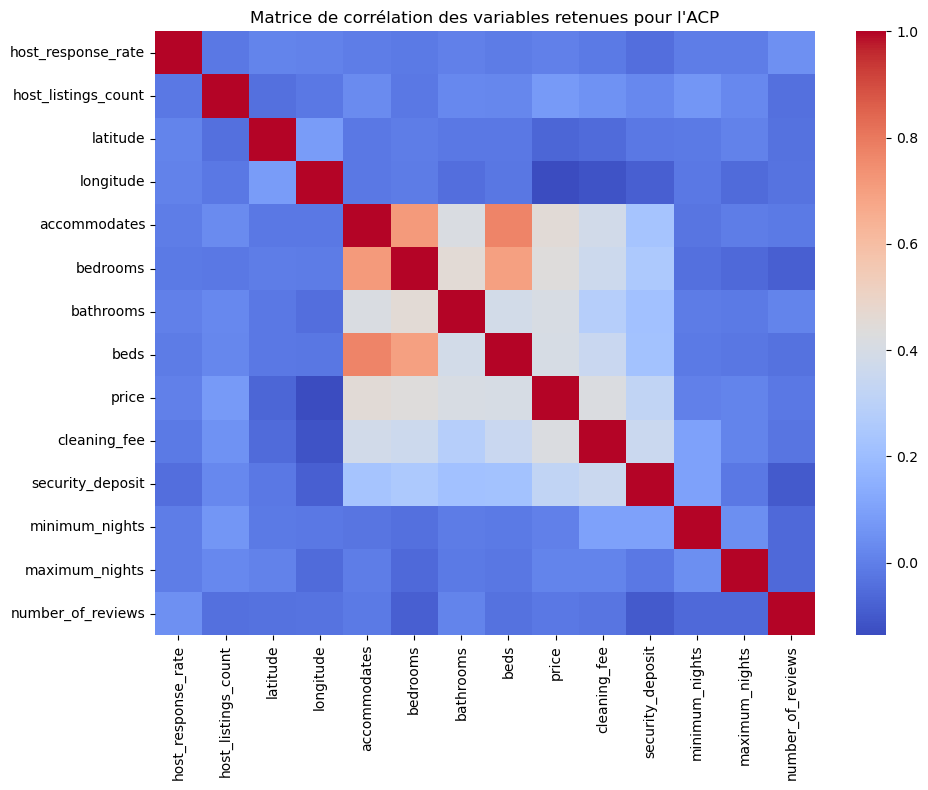

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

# Matrice de corrélation sur les variables numériques préparées pour l'ACP
corr_matrix = df_pca.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", annot=False)
plt.title("Matrice de corrélation des variables retenues pour l'ACP")
plt.tight_layout()

plt.savefig("../out_puts/correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

### Pourquoi cette preparation est necessaire avant une ACP ?

L'ACP repose sur des calculs matriciels entre variables quantitatives. Il faut donc disposer d'un tableau
coherent, numerique et sans valeurs manquantes. Cette preparation evite des erreurs techniques, rend les
variables comparables dans leur forme brute, et pose une base propre pour l'etape suivante de l'analyse.

# Etape 3 - Standardisation et calcul de l'ACP

Objectif de cette etape : standardiser les variables quantitatives preparees, puis calculer une ACP
sur l'ensemble des composantes possibles. A ce stade, on met en place les calculs, sans encore
interpreter les axes en detail et sans choisir le nombre final de composantes a retenir.

## 3.1 Pourquoi standardiser avant une ACP ?

Les variables retenues pour l'ACP n'ont pas la meme unite ni le meme ordre de grandeur : par exemple,
`price`, `maximum_nights`, `latitude` ou `number_of_reviews` ne varient pas sur les memes echelles.
Or, l'ACP repose sur la variance des variables. Sans standardisation, les variables les plus dispersees
risqueraient de dominer artificiellement l'analyse. On centre donc les variables et on les reduit pour
leur donner un poids comparable dans le calcul des composantes principales.

In [ ]:
# Import des outils necessaires pour la standardisation et l'ACP.
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardisation des variables quantitatives preparees a l'etape precedente.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_pca)

# On remet le resultat dans un dataframe pour conserver les noms de colonnes.
df_pca_scaled = pd.DataFrame(
    X_scaled,
    columns=df_pca.columns,
    index=df_pca.index,
)

# Verification rapide : apres standardisation, la moyenne doit etre proche de 0
# et l'ecart-type (population) proche de 1 pour chaque variable.
scaled_means = df_pca_scaled.mean().round(6).rename("mean_after_scaling")
scaled_stds = df_pca_scaled.std(ddof=0).round(6).rename("std_after_scaling")

print("Dimension du tableau standardise :", df_pca_scaled.shape)
display(scaled_means)
display(scaled_stds)

Dimension du tableau standardise : (8000, 14)


host_response_rate    -0.0
host_listings_count   -0.0
latitude              -0.0
longitude              0.0
accommodates           0.0
bedrooms               0.0
bathrooms             -0.0
beds                   0.0
price                 -0.0
cleaning_fee          -0.0
security_deposit      -0.0
minimum_nights        -0.0
maximum_nights         0.0
number_of_reviews     -0.0
Name: mean_after_scaling, dtype: float64

host_response_rate     1.0
host_listings_count    1.0
latitude               1.0
longitude              1.0
accommodates           1.0
bedrooms               1.0
bathrooms              1.0
beds                   1.0
price                  1.0
cleaning_fee           1.0
security_deposit       1.0
minimum_nights         1.0
maximum_nights         1.0
number_of_reviews      1.0
Name: std_after_scaling, dtype: float64

## 3.2 Calcul de l'ACP sur toutes les composantes

On applique maintenant une ACP sur l'ensemble des composantes possibles. Comme le tableau contient
14 variables quantitatives, l'ACP peut produire jusqu'a 14 composantes principales.

Les **scores projetes** correspondent aux coordonnees des individus dans le nouvel espace forme par
les composantes principales. Chaque ligne du dataset est donc representee par de nouvelles coordonnees
sur les axes `PC1`, `PC2`, `PC3`, etc. Ces scores serviront plus tard a visualiser et analyser la
structure du nuage de points dans l'espace factoriel.

In [ ]:
# Calcul de l'ACP sur toutes les composantes possibles.
pca = PCA()
scores = pca.fit_transform(df_pca_scaled)

# Construction d'un dataframe des coordonnees projetees.
score_columns = [f"PC{i}" for i in range(1, scores.shape[1] + 1)]
df_scores = pd.DataFrame(scores, columns=score_columns, index=df_pca.index)

print("Dimension du tableau des scores :", df_scores.shape)
display(df_scores.head())

Dimension du tableau des scores : (8000, 14)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14
0,-1.853873,0.970460,1.482040,-0.763906,0.108578,0.118113,-1.323799,-0.727527,-0.354956,0.483036,1.140304,-0.378924,-0.381598,0.587675
1,-1.715620,-0.470731,1.902241,-0.519713,0.589132,0.525923,0.367996,0.631613,0.477193,0.071845,0.639270,0.267887,-0.605540,-0.060610
2,0.515500,-1.219249,2.079932,-0.437322,0.787876,0.539182,0.911846,1.318007,-0.137874,-0.846102,0.110206,0.001143,0.747115,0.088398
3,-0.830675,-0.619526,-0.841317,-0.223310,0.472229,0.444945,-0.606789,-0.143272,0.680002,0.069140,0.402727,0.127005,0.026942,0.357093
4,1.642738,5.377840,-1.645923,-1.701423,2.963029,-1.295895,0.318866,2.388070,0.328907,-1.397333,2.492692,-2.294494,0.264066,-0.114114


### Transition vers l'etape suivante

Le calcul de l'ACP est maintenant en place. L'etape suivante consistera a etudier la variance
expliquee par les composantes et a determiner combien de composantes il est pertinent de retenir
pour la suite de l'analyse.

# Etape 4 - Variance expliquee et choix des composantes

Objectif de cette etape : analyser la part de variance captee par chaque composante principale,
puis disposer d'elements pour choisir combien de dimensions conserver pour la suite de l'etude.

Dans cette partie, on n'interprete pas encore le sens des axes : on se concentre uniquement sur
la quantite d'information conservee par les composantes.

## 4.1 Qu'est-ce que la variance expliquee ?

En ACP, chaque composante principale resume une partie de l'information presente dans les donnees
standardisees. Cette information est mesuree par la **variance expliquee**.

- La `variance expliquee` d'une composante indique la proportion d'information captee par cette composante.
- La `variance cumulee` additionne progressivement les proportions expliquees par `PC1`, puis `PC1 + PC2`,
  puis `PC1 + PC2 + PC3`, etc.

Ces indicateurs servent a evaluer si quelques composantes suffisent a resumer convenablement le jeu de donnees.

In [ ]:
# Extraction des quantites utiles a partir de l'ACP deja calculee.
explained_variance = pca.explained_variance_
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance_ratio = explained_variance_ratio.cumsum()

# Construction d'un tableau de synthese par composante.
components = [f"PC{i}" for i in range(1, len(explained_variance_ratio) + 1)]
variance_table = pd.DataFrame({
    "composante": components,
    "valeur_propre": explained_variance,
    "variance_expliquee": explained_variance_ratio * 100,
    "variance_cumulee": cumulative_variance_ratio * 100,
})

# Arrondi pour une lecture plus confortable dans le notebook.
variance_table[["valeur_propre", "variance_expliquee", "variance_cumulee"]] = (
    variance_table[["valeur_propre", "variance_expliquee", "variance_cumulee"]].round(4)
)

display(variance_table)

,composante,valeur_propre,variance_expliquee,variance_cumulee
0,PC1,3.5451,25.3189,25.3189
1,PC2,1.3000,9.2843,34.6032
2,PC3,1.1317,8.0826,42.6858
3,PC4,1.0102,7.2150,49.9008
4,PC5,1.0013,7.1512,57.0520
5,PC6,0.9937,7.0972,64.1493
6,PC7,0.9184,6.5590,70.7083
7,PC8,0.9040,6.4564,77.1647
8,PC9,0.8221,5.8718,83.0365
9,PC10,0.7010,5.0068,88.0432


## 4.2 Visualisation de la variance expliquee

Les deux graphiques ci-dessous sont complementaires :

- le **scree plot** montre la part de variance expliquee par chaque composante prise isolement ;
- la **courbe de variance cumulee** montre combien d'information totale est conservee
  lorsque l'on retient les premieres composantes.

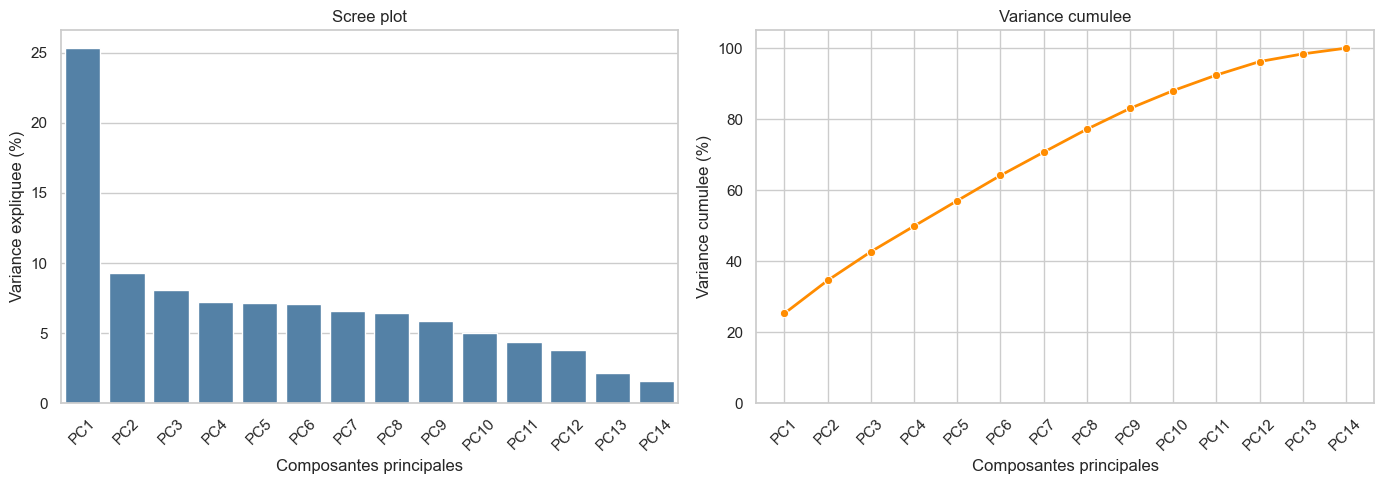

In [ ]:
# Visualisation de la variance expliquee avec matplotlib et seaborn.
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scree plot : variance expliquee par composante.
sns.barplot(
    data=variance_table,
    x="composante",
    y="variance_expliquee",
    color="steelblue",
    ax=axes[0],
)
axes[0].set_title("Scree plot")
axes[0].set_xlabel("Composantes principales")
axes[0].set_ylabel("Variance expliquee (%)")
axes[0].tick_params(axis="x", rotation=45)

# 2. Courbe de variance cumulee.
sns.lineplot(
    data=variance_table,
    x="composante",
    y="variance_cumulee",
    marker="o",
    linewidth=2,
    color="darkorange",
    ax=axes[1],
)
axes[1].set_title("Variance cumulee")
axes[1].set_xlabel("Composantes principales")
axes[1].set_ylabel("Variance cumulee (%)")
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#sauvgarder les deux plot qu'on vient de faire
variance_table.to_excel("../images/explained_variance_table.xlsx", index=False)

In [ ]:
#sauvgarder le tableux qui explique la variance expliquee par chaque composante
fig.savefig("../images/variance_plots.png", dpi=300, bbox_inches="tight")

## 4.3 Comment lire ces graphiques et choisir le nombre de composantes ?

Le **scree plot** permet de voir si les premieres composantes concentrent une grande partie de la variance.
On recherche souvent un point ou la baisse devient moins marquee : cela suggere qu'ajouter de nouvelles
composantes apporte ensuite un gain plus limite.

La **courbe de variance cumulee** permet de fixer un seuil de conservation de l'information, par exemple
70 %, 80 % ou 90 % selon l'objectif de l'analyse. On choisit alors le plus petit nombre de composantes
permettant d'atteindre ce seuil.

En pratique, le choix du nombre de composantes repose souvent sur plusieurs criteres combines :
- la forme du scree plot ;
- le niveau de variance cumulee atteint ;
- l'objectif pedagogique ou analytique de la reduction de dimension.

### Transition vers l'etape suivante

La variance expliquee permet maintenant d'avoir une premiere base pour choisir le nombre de composantes
a retenir. La prochaine etape portera sur l'analyse des **loadings**, afin d'interpreter les composantes
principales a partir de la contribution des variables initiales.

# Etape 5 - Loadings et interpretation des composantes principales

Objectif de cette etape : identifier quelles variables contribuent le plus a chaque composante
principale, afin de preparer l'interpretation de `PC1`, `PC2` et `PC3`.

Dans cette partie, on reste dans une logique descriptive : on repere les variables importantes,
sans encore faire l'interpretation metier finale dans le contexte Airbnb.

## 5.1 Qu'est-ce qu'un loading ?

En ACP, un **loading** est le coefficient associe a une variable d'origine dans la construction
d'une composante principale. Il indique a quel point la variable participe a l'axe considere.

- Un loading de grande amplitude signale une variable importante pour la composante.
- On regarde souvent la **valeur absolue** du coefficient, car un coefficient tres positif ou tres
  negatif traduit dans les deux cas une forte influence sur l'axe.
- Le **signe** du loading renseigne la direction : deux variables de meme signe evoluent dans le meme
  sens sur la composante, tandis que des signes opposes indiquent des contributions en sens contraire.

In [ ]:
# Extraction des loadings a partir des composantes de l'ACP.
# `pca.components_` contient une ligne par composante principale et une colonne par variable.
# On transpose pour obtenir un tableau plus lisible : lignes = variables, colonnes = composantes.
loadings_table = pd.DataFrame(
    pca.components_.T,
    index=df_pca.columns,
    columns=[f"PC{i}" for i in range(1, pca.components_.shape[0] + 1)],
)

display(loadings_table)

## 5.2 Focalisation sur les trois premieres composantes

Les premieres composantes sont generalement les plus importantes pour resumer l'information du jeu
de donnees. On extrait donc ici un sous-tableau centre sur `PC1`, `PC2` et `PC3`.

In [ ]:
# Sous-tableau centre sur les trois premieres composantes principales.
loadings_pc123 = loadings_table[["PC1", "PC2", "PC3"]].copy()
display(loadings_pc123)

## 5.3 Variables les plus influentes pour PC1, PC2 et PC3

Pour chaque composante, on trie les variables selon la valeur absolue de leur loading. Cela permet
de reperer rapidement les variables qui structurent le plus fortement l'axe.

In [ ]:
# Fonction utilitaire pour classer les variables par importance sur une composante donnee.
def get_sorted_loadings(loadings_df: pd.DataFrame, component_name: str) -> pd.DataFrame:
    sorted_loadings = loadings_df[[component_name]].copy()
    sorted_loadings = sorted_loadings.rename(columns={component_name: "loading"})
    sorted_loadings["abs_loading"] = sorted_loadings["loading"].abs()
    sorted_loadings = sorted_loadings.sort_values("abs_loading", ascending=False)
    return sorted_loadings

top_loadings_pc1 = get_sorted_loadings(loadings_table, "PC1")
top_loadings_pc2 = get_sorted_loadings(loadings_table, "PC2")
top_loadings_pc3 = get_sorted_loadings(loadings_table, "PC3")

print("Variables les plus influentes sur PC1")
display(top_loadings_pc1)

print("Variables les plus influentes sur PC2")
display(top_loadings_pc2)

print("Variables les plus influentes sur PC3")
display(top_loadings_pc3)

## 5.4 Visualisation des loadings sur le plan PC1-PC2

Le graphique suivant positionne chaque variable selon ses loadings sur `PC1` et `PC2`.
Il permet de voir quelles variables contribuent fortement a ces deux premiers axes, ainsi que
le sens de leur contribution positive ou negative.

In [ ]:
# Figure principale des loadings sur le plan forme par PC1 et PC2.
loadings_pc1_pc2 = loadings_table[["PC1", "PC2"]].copy()

fig_loadings_pc1_pc2, ax = plt.subplots(figsize=(9, 9))
ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="gray", linewidth=1)
ax.scatter(loadings_pc1_pc2["PC1"], loadings_pc1_pc2["PC2"], color="darkred", s=60)

for variable, row in loadings_pc1_pc2.iterrows():
    ax.arrow(
        0,
        0,
        row["PC1"],
        row["PC2"],
        color="steelblue",
        alpha=0.7,
        length_includes_head=True,
        head_width=0.015,
    )
    ax.text(row["PC1"] + 0.015, row["PC2"] + 0.015, variable, fontsize=9)

max_loading = loadings_pc1_pc2.abs().to_numpy().max()
axis_limit = max_loading * 1.2
ax.set_xlim(-axis_limit, axis_limit)
ax.set_ylim(-axis_limit, axis_limit)
ax.set_xlabel("Loadings sur PC1")
ax.set_ylabel("Loadings sur PC2")
ax.set_title("Loadings des variables sur le plan PC1-PC2")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

### Conclusion de l'etape 5

On dispose maintenant d'une base claire pour identifier les variables qui structurent le plus
les premieres composantes principales. L'etape suivante consistera a interpreter ces axes dans
le contexte Airbnb, puis a produire une visualisation factorielle des individus et des variables.

## Sauvegarde des sorties importantes

La cellule suivante enregistre les principaux resultats de cette etape dans le dossier `images/`.

In [ ]:
# Sauvegarde des sorties importantes de l'etape 5.
output_dir = Path("../images")
if not output_dir.exists():
    output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "loadings_table.csv"
xlsx_path = output_dir / "loadings_table.xlsx"
png_path = output_dir / "loadings_pc1_pc2.png"

loadings_table.to_csv(csv_path, index=True)

xlsx_saved = True
try:
    loadings_table.to_excel(xlsx_path, index=True)
except Exception as exc:
    xlsx_saved = False
    print(f"Export XLSX non disponible dans l'environnement actuel : {exc}")

fig_loadings_pc1_pc2.savefig(png_path, dpi=300, bbox_inches="tight")

print(f"CSV enregistre : {csv_path.resolve()}")
print(f"PNG enregistre : {png_path.resolve()}")
print(f"XLSX enregistre : {xlsx_saved}")

# Etape complementaire - Analyse du plan PC1-PC3

Objectif de cette etape : prolonger l'analyse des loadings en observant le plan `PC1-PC3`.
Cette vue ajoute une dimension supplementaire a l'exploration de l'ACP et peut faire apparaitre
des relations moins visibles sur le plan `PC1-PC2`.

## Pourquoi explorer aussi PC3 ?

Le plan `PC1-PC2` reste la visualisation principale, car il mobilise les deux premieres composantes.
Cependant, `PC3` peut porter une part d'information encore utile pour comprendre la structure
des variables. Le plan `PC1-PC3` vient donc **completer** l'analyse principale, sans la remplacer.

In [ ]:
# Sous-tableau des loadings sur le plan PC1-PC3.
# On reutilise directement le tableau des loadings deja calcule, sans modifier les objets existants.
loadings_pc1_pc3 = loadings_table[["PC1", "PC3"]].copy()
display(loadings_pc1_pc3)

In [ ]:
# Identification des variables les plus importantes sur PC1 et sur PC3.
# Le tri se fait selon la valeur absolue des loadings pour reperer les contributions les plus fortes.
top_loadings_pc1_pc1_pc3 = get_sorted_loadings(loadings_table, "PC1")
top_loadings_pc3_pc1_pc3 = get_sorted_loadings(loadings_table, "PC3")

print("Variables les plus influentes sur PC1 (analyse PC1-PC3)")
display(top_loadings_pc1_pc1_pc3)

print("Variables les plus influentes sur PC3 (analyse PC1-PC3)")
display(top_loadings_pc3_pc1_pc3)

In [ ]:
# Visualisation des loadings des variables sur le plan PC1-PC3.
# On conserve le meme style que pour le plan PC1-PC2 afin de faciliter la comparaison.
fig_loadings_pc1_pc3, ax = plt.subplots(figsize=(9, 9))
ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="gray", linewidth=1)
ax.scatter(loadings_pc1_pc3["PC1"], loadings_pc1_pc3["PC3"], color="darkred", s=60)

for variable, row in loadings_pc1_pc3.iterrows():
    ax.arrow(
        0,
        0,
        row["PC1"],
        row["PC3"],
        color="steelblue",
        alpha=0.7,
        length_includes_head=True,
        head_width=0.015,
    )
    ax.text(row["PC1"] + 0.015, row["PC3"] + 0.015, variable, fontsize=9)

max_loading_pc1_pc3 = loadings_pc1_pc3.abs().to_numpy().max()
axis_limit_pc1_pc3 = max_loading_pc1_pc3 * 1.2
ax.set_xlim(-axis_limit_pc1_pc3, axis_limit_pc1_pc3)
ax.set_ylim(-axis_limit_pc1_pc3, axis_limit_pc1_pc3)
ax.set_xlabel("Loadings sur PC1")
ax.set_ylabel("Loadings sur PC3")
ax.set_title("Loadings des variables sur le plan PC1-PC3")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

In [ ]:
# Sauvegarde du sous-tableau PC1-PC3 et de la figure associee.
output_dir = Path("../images")
if not output_dir.exists():
    output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

loadings_pc1_pc3_table_path = output_dir / "loadings_pc1_pc3_table.csv"
loadings_pc1_pc3_png_path = output_dir / "loadings_pc1_pc3.png"

loadings_pc1_pc3.to_csv(loadings_pc1_pc3_table_path, index=True)
fig_loadings_pc1_pc3.savefig(loadings_pc1_pc3_png_path, dpi=300, bbox_inches="tight")

print(f"Tableau PC1-PC3 enregistre : {loadings_pc1_pc3_table_path.resolve()}")
print(f"Figure PC1-PC3 enregistree : {loadings_pc1_pc3_png_path.resolve()}")

# Choix des composantes principales retenues

En ACP, le nombre de composantes retenues depend toujours de l'objectif poursuivi. Selon le cas, on
peut privilegier :
- la **visualisation**, en gardant peu de dimensions pour conserver une lecture simple ;
- l'**interpretation**, en ajoutant une composante supplementaire si elle apporte un eclairage utile ;
- la **conservation d'une part importante de la variance**, en retenant davantage de composantes afin
  de preserver plus d'information globale du jeu de donnees.

In [ ]:
# Synthese des choix de composantes retenues selon l'objectif de l'analyse.
variance_2 = variance_table.loc[1, "variance_cumulee"]
variance_3 = variance_table.loc[2, "variance_cumulee"]
variance_8 = variance_table.loc[7, "variance_cumulee"]

choices_summary = pd.DataFrame({
    "objectif": [
        "Visualisation principale",
        "Interpretation des composantes",
        "Conservation d'une plus grande part de variance",
    ],
    "composantes_retenues": [
        "PC1 et PC2",
        "PC1, PC2 et PC3",
        "8 premieres composantes",
    ],
    "variance_cumulee_associee_pct": [variance_2, variance_3, variance_8],
})

choices_summary["variance_cumulee_associee_pct"] = choices_summary["variance_cumulee_associee_pct"].round(2)
display(choices_summary)

print(f"Variance cumulee pour 2 composantes : {variance_2:.2f} %")
print(f"Variance cumulee pour 3 composantes : {variance_3:.2f} %")
print(f"Variance cumulee pour 8 composantes : {variance_8:.2f} %")

,objectif,composantes_retenues,variance_cumulee_associee_pct
0,Visualisation principale,PC1 et PC2,34.60
1,Interpretation des composantes,"PC1, PC2 et PC3",42.69
2,Conservation d'une plus grande part de variance,8 premieres composantes,77.16


Variance cumulee pour 2 composantes : 34.60 %
Variance cumulee pour 3 composantes : 42.69 %
Variance cumulee pour 8 composantes : 77.16 %


Cette selection doit etre comprise comme un **compromis** entre lisibilite, interpretabilite et
quantite d'information conservee. Peu de composantes facilitent la lecture, tandis qu'un nombre plus
eleve preserve davantage de variance mais rend l'analyse moins synthetique.

# Projection des individus sur le plan factoriel PC1-PC2

Objectif de cette derniere section : visualiser les annonces Airbnb dans le plan forme par les deux
premieres composantes principales, puis completer cette lecture par une coloration selon le type de
logement lorsque cette information est disponible dans le dataset d'origine.

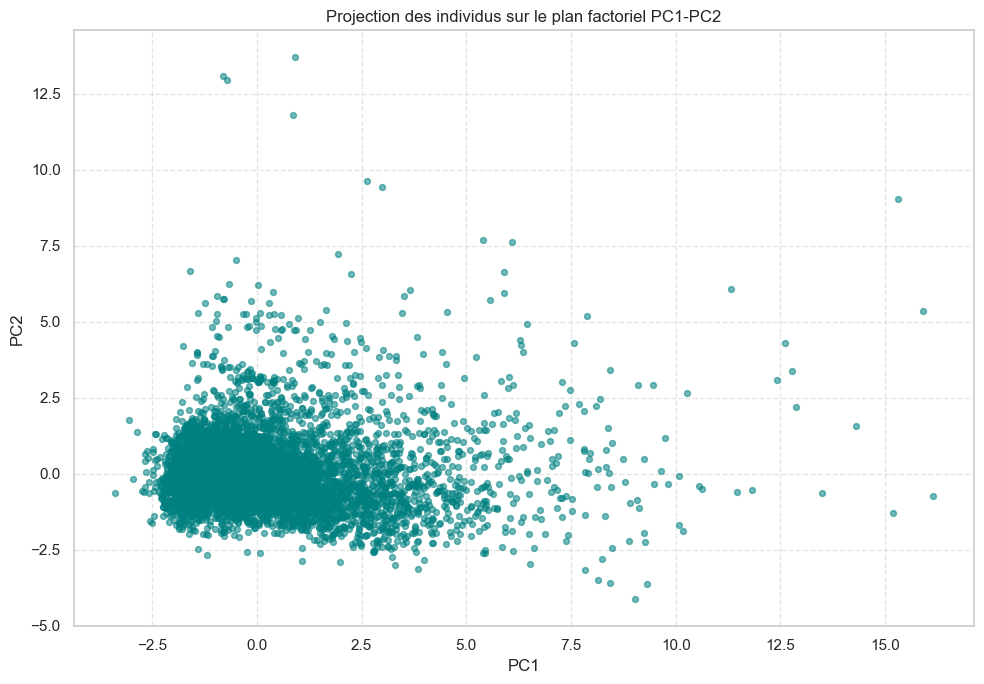

Figure enregistree : C:\Users\user\Desktop\Edam\ids3\S2\stat multivariee\projet\images\individuals_pc1_pc2.png


In [ ]:
# Projection simple des individus sur le plan factoriel PC1-PC2.
# On reutilise directement `df_scores`, sans recalculer l'ACP.
fig_individuals_pc1_pc2, ax = plt.subplots(figsize=(10, 7))
ax.scatter(df_scores["PC1"], df_scores["PC2"], s=18, alpha=0.55, color="teal")
ax.set_title("Projection des individus sur le plan factoriel PC1-PC2")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Sauvegarde de la figure principale.
output_dir = Path("../images")
if not output_dir.exists():
    output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

individuals_pc1_pc2_path = output_dir / "individuals_pc1_pc2.png"
fig_individuals_pc1_pc2.savefig(individuals_pc1_pc2_path, dpi=300, bbox_inches="tight")
print(f"Figure enregistree : {individuals_pc1_pc2_path.resolve()}")

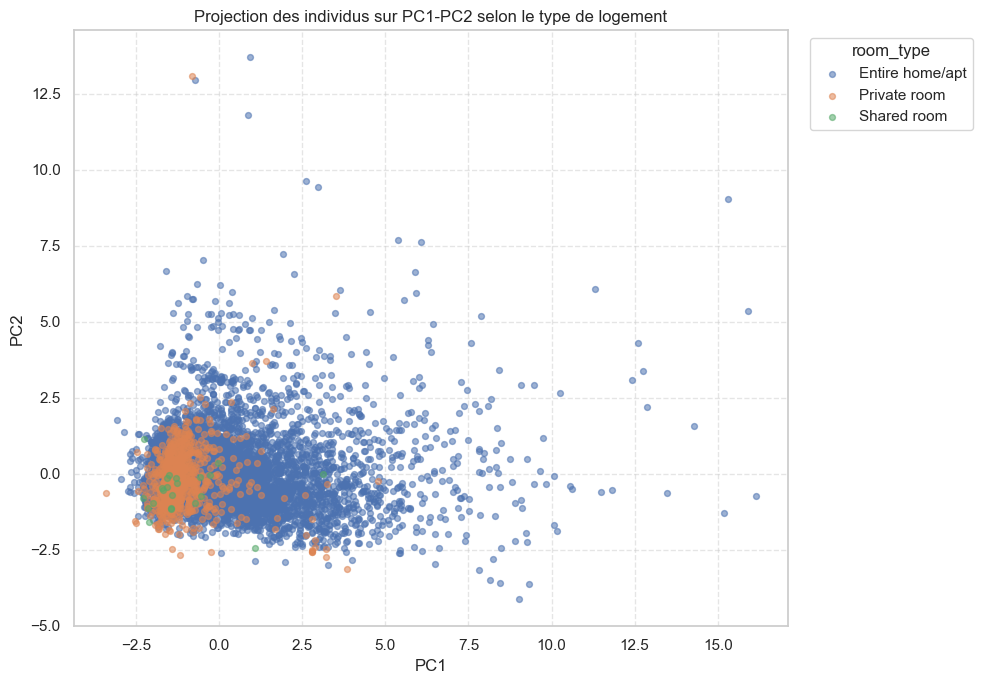

Figure coloree enregistree : C:\Users\user\Desktop\Edam\ids3\S2\stat multivariee\projet\images\individuals_pc1_pc2_by_room_type.png


In [ ]:
# Visualisation coloree par type de logement si `room_type` existe dans le dataframe original.
if "room_type" in df.columns:
    plot_df_room_type = df_scores[["PC1", "PC2"]].copy()
    plot_df_room_type["room_type"] = df.loc[df_scores.index, "room_type"].astype("string").fillna("Non renseigne")

    fig_individuals_pc1_pc2_by_room_type, ax = plt.subplots(figsize=(10, 7))
    for room_type, group in plot_df_room_type.groupby("room_type"):
        ax.scatter(group["PC1"], group["PC2"], s=18, alpha=0.55, label=room_type)

    ax.set_title("Projection des individus sur PC1-PC2 selon le type de logement")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(title="room_type", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    individuals_pc1_pc2_room_type_path = output_dir / "individuals_pc1_pc2_by_room_type.png"
    fig_individuals_pc1_pc2_by_room_type.savefig(individuals_pc1_pc2_room_type_path, dpi=300, bbox_inches="tight")
    print(f"Figure coloree enregistree : {individuals_pc1_pc2_room_type_path.resolve()}")
else:
    print("La colonne `room_type` n'existe pas dans le dataframe original : la visualisation coloree n'a pas ete creee.")